# Практическая работа: анализ двух бинарных выборок

**Цель:** определить минимальный размер выборки для MDE, получить нормальные приближения по ЦПТ, визуализировать ошибки I и II рода и построить 95%-е доверительные интервалы.

**Исходные параметры:** $p_1=0.35$, $p_2=0.40$, уровень значимости $\alpha=0.05$, мощность $1-\beta=0.80$, $\mathrm{MDE}=|p_1-p_2|=0.05$.

Вначале рассчитаем необходимый размер **равных** групп, затем сравним его с заданным примером **неравных** групп: $n_1=735$, $n_2=7350$.

> $\alpha=0.05$ — это **заданный уровень значимости**, а не вычисленное p-value. Фактические бинарные наблюдения не представлены: вероятности $p_1,p_2$ используются как параметры модели, а при построении иллюстративных доверительных интервалов — как подстановочные оценки долей.

## 1. Минимальный размер выборки

Для двух независимых пропорций при двусторонней альтернативе и равных размерах групп используем формулу из условия:

$$
\bar p=\frac{p_1+p_2}{2},\qquad
n=\frac{\left[z_{1-\alpha/2}\sqrt{2\bar p(1-\bar p)}+z_{1-\beta}\sqrt{p_1(1-p_1)+p_2(1-p_2)}\right]^2}{(p_1-p_2)^2}.
$$

Округляем результат **вверх**, чтобы не уменьшить запланированный объем выборки.

In [1]:
from math import ceil, sqrt

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

p1, p2 = 0.35, 0.40
alpha = 0.05
target_power = 0.80
mde = abs(p2 - p1)

p_bar = (p1 + p2) / 2
z_two = norm.ppf(1 - alpha / 2)
z_power = norm.ppf(target_power)

n_raw = (
    (z_two * sqrt(2 * p_bar * (1 - p_bar))
     + z_power * sqrt(p1 * (1 - p1) + p2 * (1 - p2))) / mde
) ** 2
n_equal = ceil(n_raw)

print(f"Доли: {p1:.2f} и {p2:.2f}    MDE: {mde:.2f}")
print(f"Уровень значимости: {alpha:.2f}    Целевая мощность: {target_power:.2f}")
print(f"Расчётный размер группы: {n_raw:.4f}")
print(f"Минимум по формуле: {n_equal} в каждой группе, всего {2 * n_equal}.")

Доли: 0.35 и 0.40    MDE: 0.05
Уровень значимости: 0.05    Целевая мощность: 0.80
Расчётный размер группы: 1470.4855
Минимум по формуле: 1471 в каждой группе, всего 2942.


## 2. Преобразование распределений через ЦПТ

Если $X_i\sim\mathrm{Bin}(n_i,p_i)$, то выборочная доля $\hat p_i=X_i/n_i$ при достаточно больших $n_ip_i$ и $n_i(1-p_i)$ приближенно распределена нормально:

$$
\hat p_i\approx \mathcal N\left(\mu_i=p_i,\ \sigma_i^2=\frac{p_i(1-p_i)}{n_i}\right),\qquad
\sigma_i=\sqrt{\frac{p_i(1-p_i)}{n_i}}.
$$

Здесь $\sigma$ — **стандартное отклонение**, а второй параметр стандартной записи нормального распределения $\mathcal N(\mu,\sigma^2)$ — **дисперсия**.

In [2]:
def proportion_se(p, n):
    return sqrt(p * (1 - p) / n)


designs = {
    "Равные группы": (n_equal, n_equal),
    "Неравные группы": (735, 7350),
}

for label, (n1, n2) in designs.items():
    print(f"{label} (n₁ = {n1}, n₂ = {n2})")
    for i, (p, n) in enumerate([(p1, n1), (p2, n2)], start=1):
        print(f"  Группа {i}: μ = {p:.4f}, σ = {proportion_se(p, n):.4f}")

Равные группы (n₁ = 1471, n₂ = 1471)
  Группа 1: μ = 0.3500, σ = 0.0124
  Группа 2: μ = 0.4000, σ = 0.0128
Неравные группы (n₁ = 735, n₂ = 7350)
  Группа 1: μ = 0.3500, σ = 0.0176
  Группа 2: μ = 0.4000, σ = 0.0057


## 3. Визуализация распределений и статистических ошибок

В каждом рисунке:
- **слева** — распределения выборочных долей двух групп и вертикальные линии их средних;
- **справа** — распределения $Z$-статистики при граничной нулевой гипотезе ($H_0$) и при конкретной альтернативе ($H_1$);
- **синяя заливка** — область отклонения $H_0$ под нулевой гипотезой; ее площадь равна $\alpha$;
- **красная заливка** — область неотклонения $H_0$ под альтернативой; ее площадь равна $\beta$;
- пунктирные вертикальные линии — средние распределений; точечные линии — критические границы.

Площади ошибок нанесены именно **на распределения статистики теста**, а не на распределения отдельных долей: это позволяет корректно интерпретировать $\alpha$ и $\beta$.

### 3.1. Двусторонняя альтернатива

$$H_0:p_1=p_2,\qquad H_1:p_1\ne p_2.$$

Критическая область: $Z<-z_{1-\alpha/2}$ или $Z>z_{1-\alpha/2}$.

In [3]:
def z_distribution(a, b, n1, n2):
    pooled = (n1 * a + n2 * b) / (n1 + n2)
    se_null = sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    se_actual = sqrt(proportion_se(a, n1)**2 + proportion_se(b, n2)**2)
    return norm(loc=(a - b) / se_null, scale=se_actual / se_null)


blue, red, gray = "#215eb0", "#bd374e", "#525d69"


def draw_proportions(ax, n1, n2):
    distributions = [norm(p1, proportion_se(p1, n1)),
                     norm(p2, proportion_se(p2, n2))]
    low = min(d.ppf(0.0001) for d in distributions)
    high = max(d.ppf(0.9999) for d in distributions)
    x = np.linspace(low, high, 700)
    for i, (dist, color) in enumerate(zip(distributions, (blue, red)), start=1):
        ax.plot(x, dist.pdf(x), color=color, label=f"Группа {i} · μ = {dist.mean():.2f}")
        ax.axvline(dist.mean(), color=color, ls="--", lw=0.9)
    ax.set(xlabel="Выборочная доля", ylabel="Плотность")
    ax.legend(fontsize=8)


def draw_test(ax, n1, n2, one_sided):
    null = norm()
    actual = z_distribution(p1, p2, n1, n2)
    # Для односторонней демонстрации H₁: p₁>p₂ требуется положительный эффект.
    # При исходных значениях p₁<p₂, поэтому показываем отдельный
    # контрфактический сценарий p₁=0.40, p₂=0.35 (тот же MDE).
    alt = z_distribution(p2, p1, n1, n2) if one_sided else actual
    right = norm.ppf(1 - alpha) if one_sided else z_two
    left = -np.inf if one_sided else -right
    beta = alt.cdf(right) - alt.cdf(left)

    x_min = min(d.ppf(0.00005) for d in (null, actual, alt))
    x_max = max(d.ppf(0.99995) for d in (null, actual, alt))
    bounds = [right] if one_sided else [left, right]
    x = np.unique(np.r_[np.linspace(x_min, x_max, 1400), bounds])
    reject = (x <= left) | (x >= right)
    retain = (left <= x) & (x <= right)

    ax.plot(x, null.pdf(x), color=blue, label="H₀ · равные доли")
    sign = "+" if one_sided else "−"
    ax.plot(x, alt.pdf(x), color=red, label=f"H₁ · разность {sign}{mde:.2f}")
    ax.fill_between(x, null.pdf(x), where=reject, color=blue, alpha=0.40,
                    label=f"Ошибка I рода · α = {alpha:.2f}")
    ax.fill_between(x, alt.pdf(x), where=retain, color=red, alpha=0.37,
                    label=f"Ошибка II рода · β = {beta:.3f}")
    if one_sided:
        ax.plot(x, actual.pdf(x), color=gray, ls="-.",
                label=f"Исходная разность −{mde:.2f}")
        ax.axvline(actual.mean(), color=gray, ls="--", lw=0.8)
    for dist, color in [(null, blue), (alt, red)]:
        ax.axvline(dist.mean(), color=color, ls="--", lw=0.8)
    for i, bound in enumerate(bounds):
        ax.axvline(bound, color="#222222", ls=":", lw=1.4,
                   label="Критическая граница" if i == 0 else None)
    ax.set(xlabel="Статистика Z для разности долей", ylabel="Плотность")
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))

    print(f"  Критическая область: Z ≥ {right:.3f}" if one_sided else
          f"  Критические области: Z ≤ {left:.3f} или Z ≥ {right:.3f}")
    print(f"  β = {beta:.4f}, мощность = {1 - beta:.4f}")
    if one_sided:
        print(f"  P(отклонить H₀ при исходных долях) = {actual.sf(right):.2e}")


def plot_designs(one_sided):
    title = "Односторонняя альтернатива · p₁ > p₂" if one_sided else "Двусторонняя альтернатива · p₁ ≠ p₂"
    fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.0))
    fig.subplots_adjust(left=0.07, right=0.78, bottom=0.09, top=0.86,
                        wspace=0.25, hspace=0.57)
    fig.suptitle(title, x=0.07, ha="left", fontsize=17, fontweight="bold")
    for (label, (n1, n2)), (ax_p, ax_z) in zip(designs.items(), axes):
        ax_p.set_title(f"{label} · n₁ = {n1}, n₂ = {n2}", loc="left", fontsize=11)
        ax_z.set_title("Области ошибок теста", loc="left", fontsize=11)
        print(f"{label} (n₁ = {n1}, n₂ = {n2})")
        draw_proportions(ax_p, n1, n2)
        draw_test(ax_z, n1, n2, one_sided)
        for ax in (ax_p, ax_z):
            ax.set_ylim(bottom=0)
            ax.set_axisbelow(True)
            ax.grid(alpha=0.18)
            ax.spines[["top", "right"]].set_visible(False)
    plt.show()

Равные группы (n₁ = 1471, n₂ = 1471)
  Критические области: Z ≤ -1.960 или Z ≥ 1.960
  β = 0.1999, мощность = 0.8001
Неравные группы (n₁ = 735, n₂ = 7350)
  Критические области: Z ≤ -1.960 или Z ≥ 1.960
  β = 0.2423, мощность = 0.7577


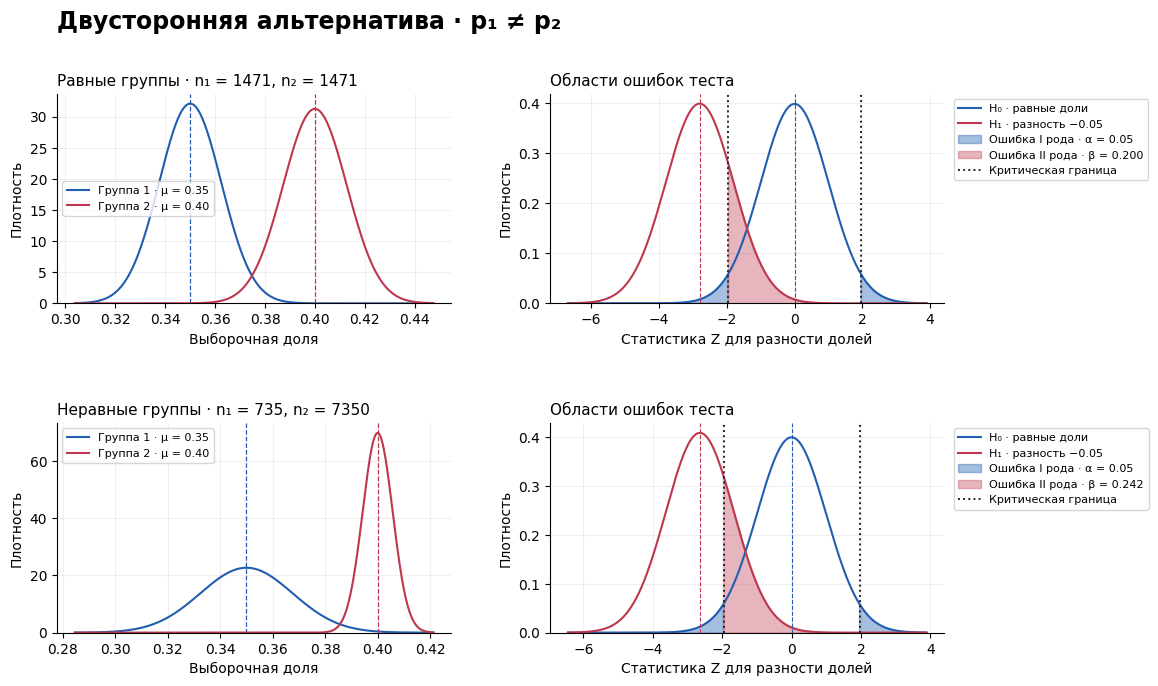

In [4]:
plot_designs(one_sided=False)

### 3.2. Односторонняя альтернатива

$$H_0:p_1\le p_2,\qquad H_1:p_1>p_2.$$

Критическая область: $Z>z_{1-\alpha}$.

**Существенное уточнение.** По исходным данным $p_1=0.35<p_2=0.40$, то есть направление эффекта **противоположно заданной альтернативе**. Поэтому для осмысленной демонстрации ошибки II рода мы дополнительно рассматриваем **условный сценарий** $p_1=0.40>p_2=0.35$, сохранив $\mathrm{MDE}=0.05$. Этот условный сценарий показан как $H_1$ на правых панелях. Исходное направление эффекта отдельно показано серой штрихпунктирной кривой.

Мощность и $\beta$, рассчитанные для этого рисунка, относятся **к условному положительному эффекту**, а не к исходному эффекту $-0.05$.

Равные группы (n₁ = 1471, n₂ = 1471)
  Критическая область: Z ≥ 1.645
  β = 0.1235, мощность = 0.8765
  P(отклонить H₀ при исходных долях) = 4.26e-06
Неравные группы (n₁ = 735, n₂ = 7350)
  Критическая область: Z ≥ 1.645
  β = 0.1504, мощность = 0.8496
  P(отклонить H₀ при исходных долях) = 5.80e-06


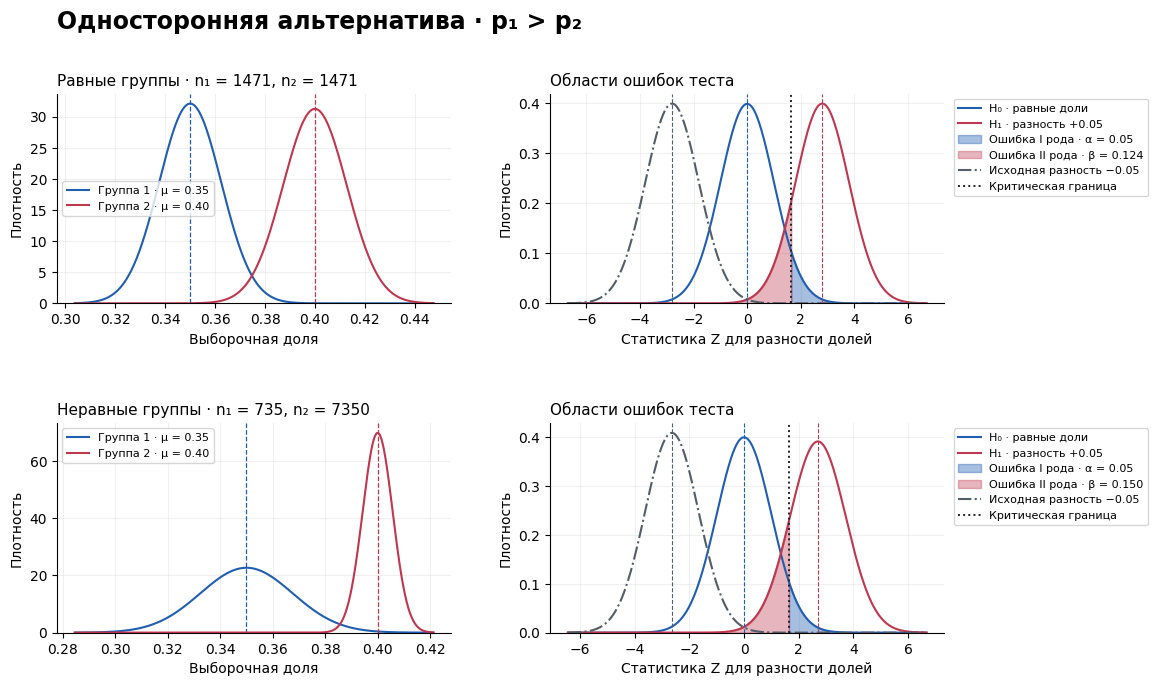

In [5]:
plot_designs(one_sided=True)

## 4. Доверительные интервалы для долей

В соответствии с заданием строим двусторонний **интервал Вальда** на уровне доверия 95%:

$$
CI_i=\hat p_i\pm z_{1-\alpha/2}\sqrt{\frac{\hat p_i(1-\hat p_i)}{n_i}}.
$$

Поскольку реальные числа успехов в группах не указаны, используем $\hat p_1=0.35$ и $\hat p_2=0.40$ в качестве **иллюстративных оценок**. Это не доверительные интервалы, вычисленные по фактически собранным данным.

In [6]:
def wald_interval(p_hat, n):
    margin = z_two * proportion_se(p_hat, n)
    return p_hat - margin, p_hat + margin


for label, (n1, n2) in designs.items():
    print(f"{label} (n₁ = {n1}, n₂ = {n2})")
    for i, (p_hat, n) in enumerate([(p1, n1), (p2, n2)], start=1):
        low, high = wald_interval(p_hat, n)
        print(f"  Группа {i}: [{low:.4f}, {high:.4f}]  (ширина: {high - low:.4f})")

Равные группы (n₁ = 1471, n₂ = 1471)
  Группа 1: [0.3256, 0.3744]  (ширина: 0.0487)
  Группа 2: [0.3750, 0.4250]  (ширина: 0.0501)
Неравные группы (n₁ = 735, n₂ = 7350)
  Группа 1: [0.3155, 0.3845]  (ширина: 0.0690)
  Группа 2: [0.3888, 0.4112]  (ширина: 0.0224)


## Выводы

1. По формуле из условия для двустороннего теста с $\alpha=0.05$ и мощностью $0.80$ необходимо **1471 наблюдение в каждой группе** (2942 суммарно).
2. По ЦПТ стандартные отклонения выборочных долей при равных группах составляют около **0.0124** и **0.0128**; при неравных — **0.0176** и **0.0057**.
3. На двустороннем графике при равных группах расчетная мощность составляет около **0.800**, при неравных ($735$ и $7350$) — около **0.758**. Даже более крупный общий объем наблюдений не гарантирует большую мощность при сильном дисбалансе групп.
4. При односторонней гипотезе $p_1>p_2$ и исходных $p_1<p_2$ ошибка II рода для заявленной альтернативы не определяется. Для ее иллюстрации приведен явно обозначенный **условный положительный эффект**.
5. Иллюстративные 95%-е интервалы в сценарии равных групп равны **[0.3256; 0.3744]** и **[0.3750; 0.4250]**; для неравных — **[0.3155; 0.3845]** и **[0.3888; 0.4112]**.